In [1]:
!wget -q "https://www.kaggle.com/api/v1/datasets/download/mohammadtalib786/retail-sales-dataset?datasetVersionNumber=1" -O retail.zip
!unzip -o retail.zip

Archive:  retail.zip
  inflating: retail_sales_dataset.csv  


In [2]:
import pandas as pd

df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (1000, 9)

Columns:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [4]:
customer_data = df.groupby('Customer ID').agg(
    Total_Spending=('Total Amount', 'sum'),
    Purchase_Frequency=('Transaction ID', 'count'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

customer_data.head()

,Customer ID,Total_Spending,Purchase_Frequency,Total_Quantity
0,CUST001,150,1,3
1,CUST002,1000,1,2
2,CUST003,30,1,1
3,CUST004,500,1,1
4,CUST005,100,1,2


In [5]:
customer_data['Average_Purchase_Value'] = (
    customer_data['Total_Spending'] /
    customer_data['Purchase_Frequency']
)

customer_data.head()

,Customer ID,Total_Spending,Purchase_Frequency,Total_Quantity,Average_Purchase_Value
0,CUST001,150,1,3,150.0
1,CUST002,1000,1,2,1000.0
2,CUST003,30,1,1,30.0
3,CUST004,500,1,1,500.0
4,CUST005,100,1,2,100.0


In [6]:
features = customer_data[
    ['Total_Spending', 'Purchase_Frequency', 'Average_Purchase_Value']
]

features.head()

,Total_Spending,Purchase_Frequency,Average_Purchase_Value
0,150,1,150.0
1,1000,1,1000.0
2,30,1,30.0
3,500,1,500.0
4,100,1,100.0


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(features)

scaled_features[:5]

array([[-0.5467043 ,  0.        , -0.5467043 ],
       [ 0.97191876,  0.        ,  0.97191876],
       [-0.76109815,  0.        , -0.76109815],
       [ 0.07861108,  0.        ,  0.07861108],
       [-0.63603507,  0.        , -0.63603507]])

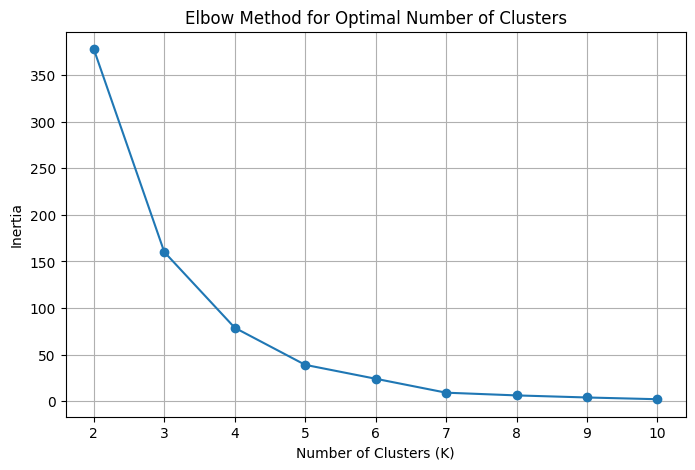

In [8]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2, 11), inertia, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

In [9]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

customer_data['Cluster'] = kmeans.fit_predict(scaled_features)

customer_data.head()

,Customer ID,Total_Spending,Purchase_Frequency,Total_Quantity,Average_Purchase_Value,Cluster
0,CUST001,150,1,3,150.0,0
1,CUST002,1000,1,2,1000.0,2
2,CUST003,30,1,1,30.0,0
3,CUST004,500,1,1,500.0,3
4,CUST005,100,1,2,100.0,0


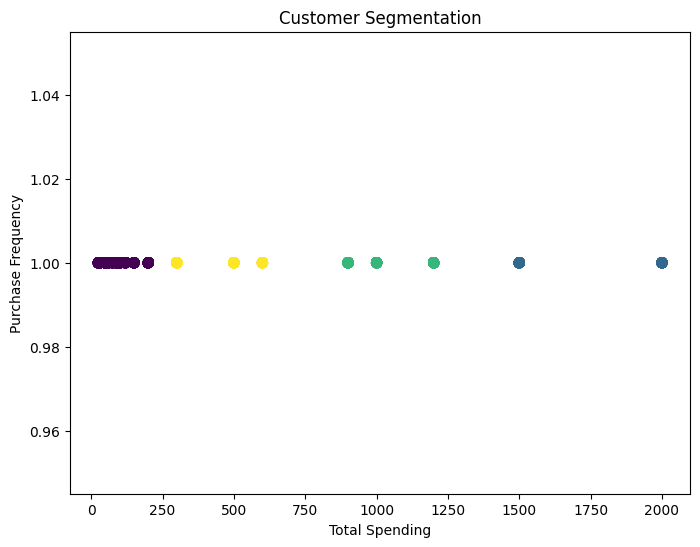

In [10]:
plt.figure(figsize=(8,6))

plt.scatter(
    customer_data['Total_Spending'],
    customer_data['Purchase_Frequency'],
    c=customer_data['Cluster'],
    s=50
)

plt.title('Customer Segmentation')
plt.xlabel('Total Spending')
plt.ylabel('Purchase Frequency')
plt.show()

In [11]:
cluster_counts = customer_data['Cluster'].value_counts().sort_index()

print(cluster_counts)

Cluster
0    604
1     99
2    165
3    132
Name: count, dtype: int64


In [12]:
cluster_profile = customer_data.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Avg_Spending=('Total_Spending', 'mean'),
    Avg_Frequency=('Purchase_Frequency', 'mean'),
    Avg_Quantity=('Total_Quantity', 'mean'),
    Avg_Purchase_Value=('Average_Purchase_Value', 'mean')
).round(2)

cluster_profile

,Customers,Avg_Spending,Avg_Frequency,Avg_Quantity,Avg_Purchase_Value
Cluster,,,,,
0,604,87.91,1.0,2.49,87.91
1,99,1747.47,1.0,3.49,1747.47
2,165,1027.88,1.0,3.03,1027.88
3,132,456.82,1.0,1.27,456.82


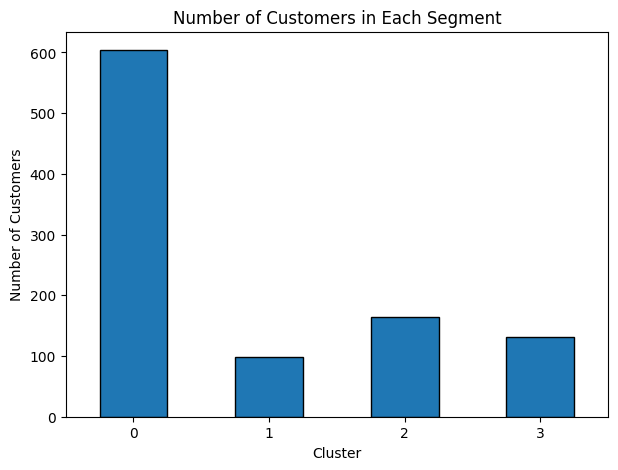

In [13]:
plt.figure(figsize=(7,5))

cluster_counts.plot(kind='bar', edgecolor='black')

plt.title('Number of Customers in Each Segment')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.show()

In [14]:
cluster_profile['Segment'] = [
    'Segment 1',
    'Segment 2',
    'Segment 3',
    'Segment 4'
]

cluster_profile

,Customers,Avg_Spending,Avg_Frequency,Avg_Quantity,Avg_Purchase_Value,Segment
Cluster,,,,,,
0,604,87.91,1.0,2.49,87.91,Segment 1
1,99,1747.47,1.0,3.49,1747.47,Segment 2
2,165,1027.88,1.0,3.03,1027.88,Segment 3
3,132,456.82,1.0,1.27,456.82,Segment 4


## Customer Segment Insights and Marketing Recommendations

### Segment 1
Target customers with personalized offers and product recommendations based on their purchasing behaviour.

### Segment 2
Use discounts and promotional campaigns to encourage more frequent purchases.

### Segment 3
Provide loyalty rewards and exclusive offers to increase customer retention.

### Segment 4
Use premium products, personalized recommendations, and loyalty benefits to increase their overall spending.

## Conclusion

K-Means clustering was used to segment customers based on spending, purchase frequency, and average purchase value. The segmentation helps identify different customer groups and supports targeted marketing strategies.